# Phase 1: First look at the results

Accuracy across languages and intents, confidence, and prediction changes between translations.

In [1]:
import csv
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Run from the folder containing this notebook.
results = Path("results")
with open(results / "translation_predictions.csv", encoding="utf-8") as f:
    predictions = list(csv.DictReader(f))
with open(results / "language_stats.csv", encoding="utf-8") as f:
    stats = list(csv.DictReader(f))

stats.sort(key=lambda row: float(row["accuracy"]), reverse=True)
locales = [row["locale"] for row in stats]
intents = sorted({row["intent"] for row in predictions})
print(f"{len(predictions):,} predictions, {len(locales)} languages, {len(intents)} intents")

99,060 predictions, 52 languages, 20 intents


## Accuracy by language and intent

Languages are ordered by overall accuracy. Brighter cells mean higher accuracy.

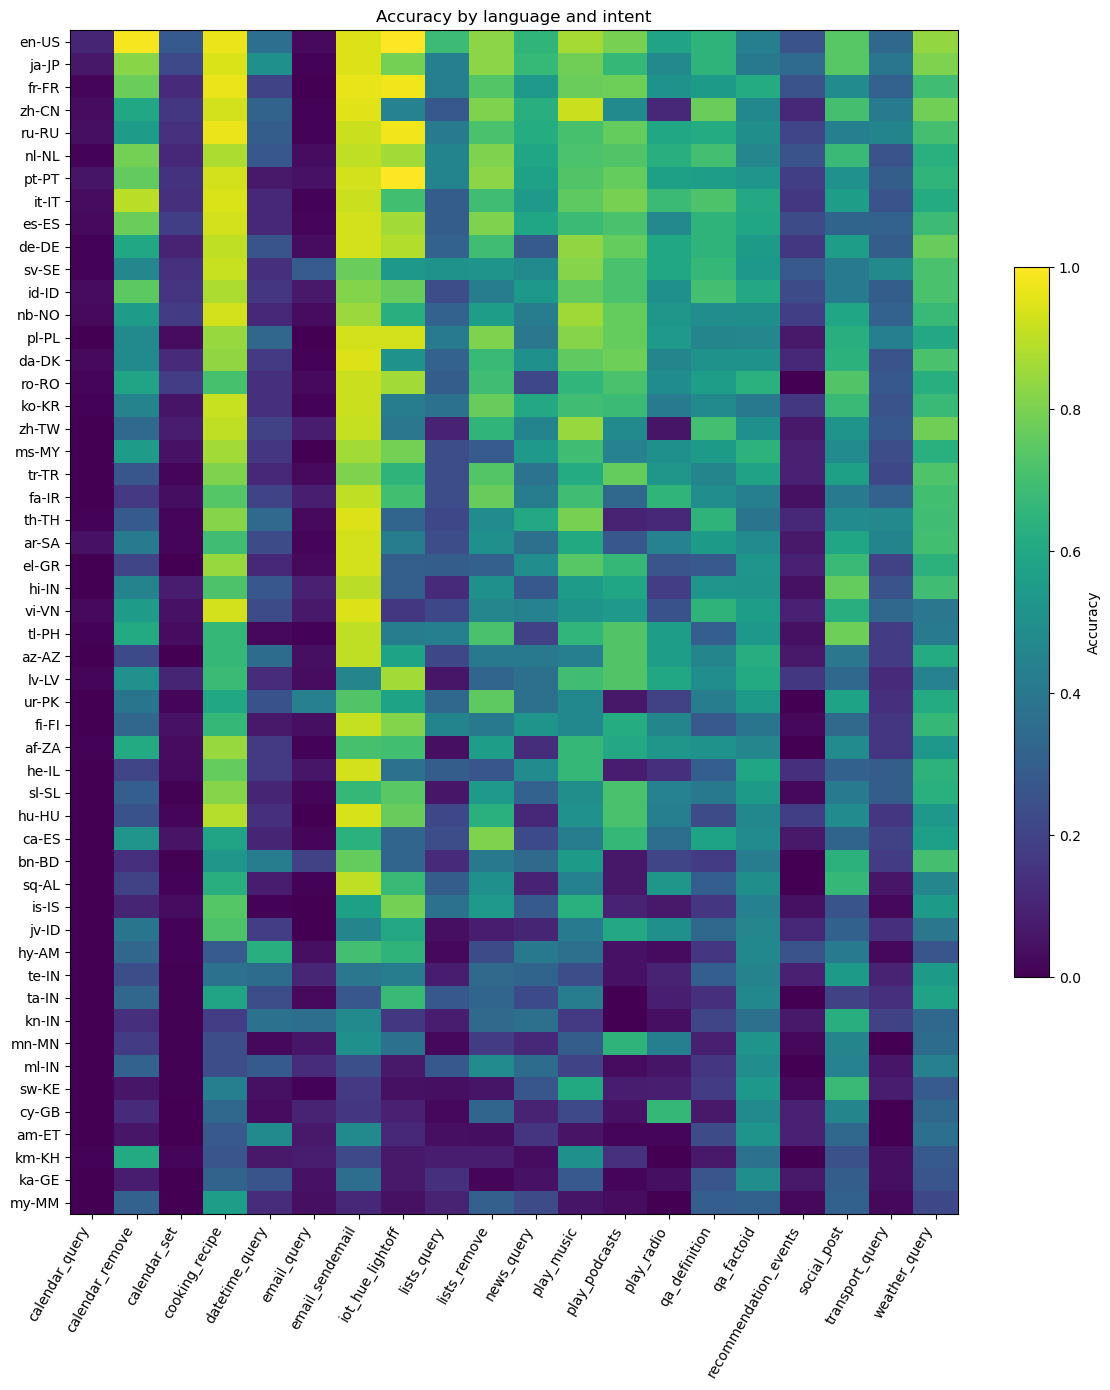

In [2]:
# Collect the correct/incorrect results for each cell.
groups = defaultdict(list)
for row in predictions:
    groups[row["locale"], row["intent"]].append(int(row["correct"]))

accuracy = np.array([
    [np.mean(groups[locale, intent]) for intent in intents]
    for locale in locales
])

fig, ax = plt.subplots(figsize=(12, 14))
image = ax.imshow(accuracy, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(intents)), intents, rotation=60, ha="right")
ax.set_yticks(range(len(locales)), locales)
ax.set_title("Accuracy by language and intent")
fig.colorbar(image, ax=ax, label="Accuracy", shrink=0.6)
plt.tight_layout()
plt.show()

## Accuracy and confidence

Does the model report higher confidence than its accuracy would suggest?

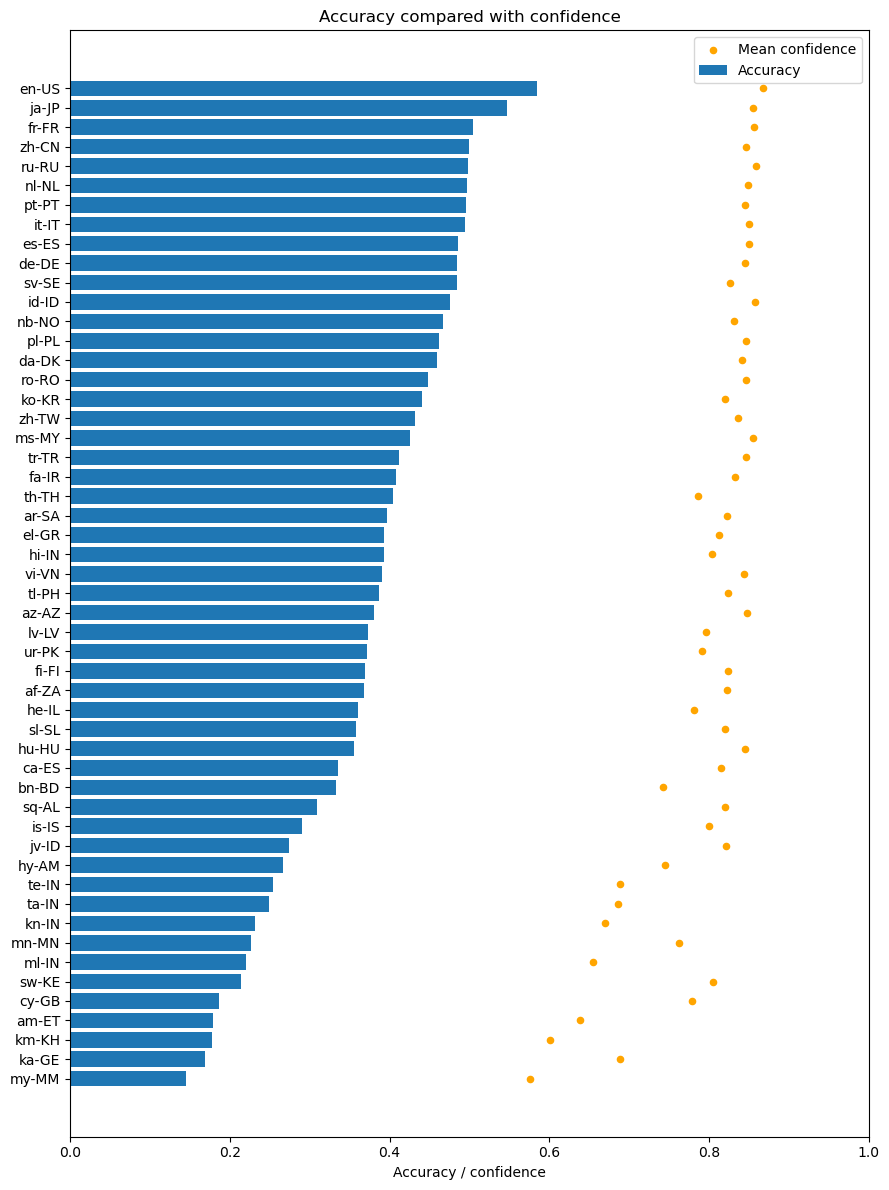

In [3]:
accuracy_by_language = [float(row["accuracy"]) for row in stats]
confidence = [float(row["mean_confidence"]) for row in stats]
y = np.arange(len(locales))

fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(y, accuracy_by_language, label="Accuracy")
ax.scatter(confidence, y, color="orange", s=20, label="Mean confidence")
ax.set_yticks(y, locales)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Accuracy / confidence")
ax.set_title("Accuracy compared with confidence")
ax.legend()
plt.tight_layout()
plt.show()

## Calibration diagram

Group all predictions into ten confidence bins and compare their mean confidence with their accuracy. On the dashed line, confidence matches accuracy. Points below the line mean the model is overconfident. Languages are pooled together here.

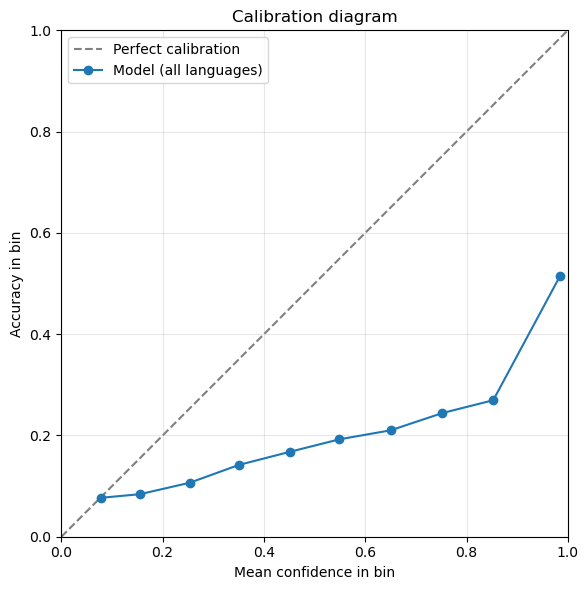

In [4]:
confidence_values = np.array([float(row["confidence"]) for row in predictions])
correct = np.array([int(row["correct"]) for row in predictions])
# Confidence 1.0 belongs in the last bin.
bin_index = np.minimum((confidence_values * 10).astype(int), 9)

bin_confidence = []
bin_accuracy = []
for i in range(10):
    selected = bin_index == i
    if selected.any():
        bin_confidence.append(confidence_values[selected].mean())
        bin_accuracy.append(correct[selected].mean())

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(bin_confidence, bin_accuracy, "o-", label="Model (all languages)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("Mean confidence in bin")
ax.set_ylabel("Accuracy in bin")
ax.set_title("Calibration diagram")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Prediction changes across translations

Count the distinct predicted labels for each utterance ID across all languages. A count of 1 means all translations received the same prediction, which can still be wrong.

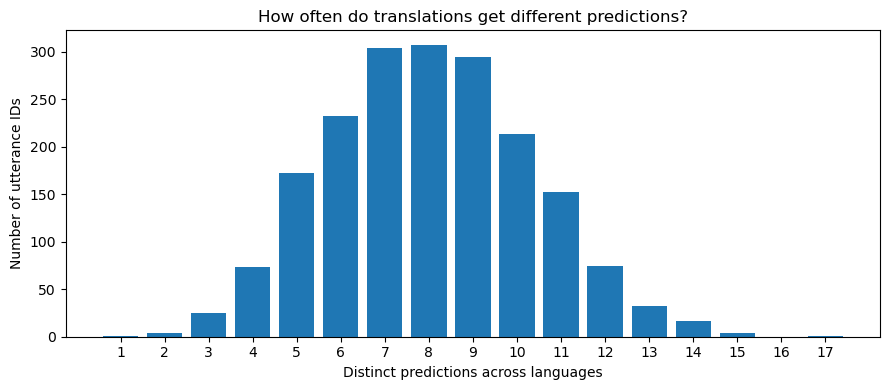

1904 out of 1905 utterances have different predictions across languages.


In [5]:
# Each ID should only count once.
predictions_by_id = defaultdict(set)
for row in predictions:
    predictions_by_id[row["id"]].add(row["pred"])

distinct = [len(labels) for labels in predictions_by_id.values()]
plt.figure(figsize=(9, 4))
plt.hist(distinct, bins=np.arange(0.5, max(distinct) + 1.5), rwidth=0.8)
plt.xticks(range(1, max(distinct) + 1))
plt.xlabel("Distinct predictions across languages")
plt.ylabel("Number of utterance IDs")
plt.title("How often do translations get different predictions?")
plt.tight_layout()
plt.show()

flips = sum(count > 1 for count in distinct)
print(f"{flips} out of {len(distinct)} utterances have different predictions across languages.")

## A closer look: removing calendar events

`calendar_remove` varies strongly across languages: accuracy ranges from 98.5% in English to 6.0% in Amharic and Swahili (67 utterances per locale). What does the model predict when it misses this intent?

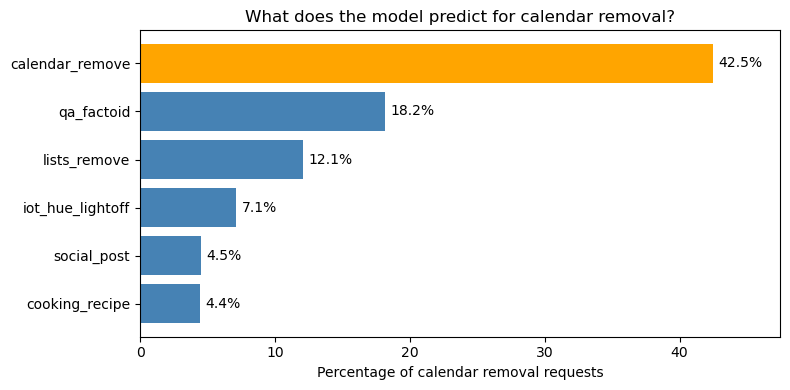

In [6]:
from collections import Counter

calendar = [row for row in predictions if row["intent"] == "calendar_remove"]
counts = Counter(row["pred"] for row in calendar)
labels = [label for label, count in counts.most_common(6)]
percentages = [100 * counts[label] / len(calendar) for label in labels]
colors = ["orange" if label == "calendar_remove" else "steelblue" for label in labels]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, percentages, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(percentages) + 5)
ax.set_xlabel("Percentage of calendar removal requests")
ax.set_title("What does the model predict for calendar removal?")
plt.tight_layout()
plt.show()

The correct label (orange) is the most common output, but many requests go to `qa_factoid` or `lists_remove`. Only the six most common outputs are shown.

Below are three random calendar removal requests, comparing English and German. The first is correct in both languages, the second is correct only in English, and the third has no correctness condition. Confidence does not affect selection. The seed is set to 42, so rerunning the cell gives the same examples. Change the seed to try another selection.

In [9]:
import random

random.seed(44)

translations = defaultdict(dict)
for row in calendar:
    if row["locale"] in ["en-US", "de-DE"]:
        translations[row["id"]][row["locale"]] = row

both_correct = []
english_only = []
for utterance_id, rows in translations.items():
    english_correct = rows["en-US"]["pred"] == "calendar_remove"
    german_correct = rows["de-DE"]["pred"] == "calendar_remove"
    if english_correct and german_correct:
        both_correct.append(utterance_id)
    if english_correct and not german_correct:
        english_only.append(utterance_id)

first = random.choice(both_correct)
second = random.choice(english_only)
third = random.choice([i for i in translations if i not in [first, second]])
examples = [("Correct in both languages", first),
            ("Wrong in German, correct in English", second),
            ("Random example", third)]

for title, utterance_id in examples:
    print(f"\n{title} - ID {utterance_id} (true intent: calendar_remove)")
    for locale in ["en-US", "de-DE"]:
        row = translations[utterance_id][locale]
        print(f"{locale}: {row['utt']}")
        print(f"  -> {row['pred']} (confidence {float(row['confidence']):.1%})")


Correct in both languages - ID 8430 (true intent: calendar_remove)
en-US: cancel all my appointments
  -> calendar_remove (confidence 100.0%)
de-DE: lösche alle mein termin
  -> calendar_remove (confidence 99.6%)

Wrong in German, correct in English - ID 8562 (true intent: calendar_remove)
en-US: delete my meeting for two o'clock p. m. today
  -> calendar_remove (confidence 100.0%)
de-DE: lösche mein treffen für heute um vierzehn uhr
  -> weather_query (confidence 98.7%)

Random example - ID 7289 (true intent: calendar_remove)
en-US: get rid of all events with jeff
  -> calendar_remove (confidence 72.3%)
de-DE: lösche alle events mit jan
  -> calendar_remove (confidence 40.2%)
